# Lesson 5: Boston housing

Explore the historical Boston housing data in `housing.csv`. The target, `MEDV`, is the median home value in thousands of dollars. Open the notebook from this folder and run the cells in order. You need pandas, Matplotlib, seaborn, and scikit-learn.

**Data:** [Boston Housing](https://www.kaggle.com/datasets/vikrishnan/boston-house-prices). Download `housing.csv` and place it in this lesson folder.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

column_names = [
    "CRIM", "ZN", "INDUS", "CHAS", "NOX", "RM", "AGE",
    "DIS", "RAD", "TAX", "PTRATIO", "B", "LSTAT", "MEDV",
]
df = pd.read_csv("housing.csv", header=None, sep=r"\s+", names=column_names)
target = "MEDV"

print("Dataset shape:", df.shape)

Dataset shape: (506, 14)


In [2]:
df.head(10)

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296.0,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242.0,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242.0,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222.0,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222.0,18.7,396.90,5.33,36.2
5,0.02985,0.0,2.18,0,0.458,6.430,58.7,6.0622,3,222.0,18.7,394.12,5.21,28.7
6,0.08829,12.5,7.87,0,0.524,6.012,66.6,5.5605,5,311.0,15.2,395.60,12.43,22.9
7,0.14455,12.5,7.87,0,0.524,6.172,96.1,5.9505,5,311.0,15.2,396.90,19.15,27.1
8,0.21124,12.5,7.87,0,0.524,5.631,100.0,6.0821,5,311.0,15.2,386.63,29.93,16.5
9,0.17004,12.5,7.87,0,0.524,6.004,85.9,6.5921,5,311.0,15.2,386.71,17.10,18.9


In [3]:
df.dtypes

CRIM       float64
ZN         float64
INDUS      float64
CHAS         int64
NOX        float64
RM         float64
AGE        float64
DIS        float64
RAD          int64
TAX        float64
PTRATIO    float64
B          float64
LSTAT      float64
MEDV       float64
dtype: object

In [4]:
df.describe()

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
count,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000
mean,3.613524,11.363636,11.136779,0.069170,0.554695,6.284634,68.574901,3.795043,9.549407,408.237154,18.455534,356.674032,12.653063,22.532806
std,8.601545,23.322453,6.860353,0.253994,0.115878,0.702617,28.148861,2.105710,8.707259,168.537116,2.164946,91.294864,7.141062,9.197104
min,0.006320,0.000000,0.460000,0.000000,0.385000,3.561000,2.900000,1.129600,1.000000,187.000000,12.600000,0.320000,1.730000,5.000000
25%,0.082045,0.000000,5.190000,0.000000,0.449000,5.885500,45.025000,2.100175,4.000000,279.000000,17.400000,375.377500,6.950000,17.025000
50%,0.256510,0.000000,9.690000,0.000000,0.538000,6.208500,77.500000,3.207450,5.000000,330.000000,19.050000,391.440000,11.360000,21.200000
75%,3.677083,12.500000,18.100000,0.000000,0.624000,6.623500,94.075000,5.188425,24.000000,666.000000,20.200000,396.225000,16.955000,25.000000
max,88.976200,100.000000,27.740000,1.000000,0.871000,8.780000,100.000000,12.126500,24.000000,711.000000,22.000000,396.900000,37.970000,50.000000


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 506 entries, 0 to 505
Data columns (total 14 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   CRIM     506 non-null    float64
 1   ZN       506 non-null    float64
 2   INDUS    506 non-null    float64
 3   CHAS     506 non-null    int64  
 4   NOX      506 non-null    float64
 5   RM       506 non-null    float64
 6   AGE      506 non-null    float64
 7   DIS      506 non-null    float64
 8   RAD      506 non-null    int64  
 9   TAX      506 non-null    float64
 10  PTRATIO  506 non-null    float64
 11  B        506 non-null    float64
 12  LSTAT    506 non-null    float64
 13  MEDV     506 non-null    float64
dtypes: float64(12), int64(2)
memory usage: 55.5 KB


## Missing values and duplicates

Check for missing entries and count repeated rows before plotting.

In [6]:
df.isnull().sum()

CRIM       0
ZN         0
INDUS      0
CHAS       0
NOX        0
RM         0
AGE        0
DIS        0
RAD        0
TAX        0
PTRATIO    0
B          0
LSTAT      0
MEDV       0
dtype: int64

In [7]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


## Distributions

Box plots show the median and spread. Histograms show the shape of each distribution.

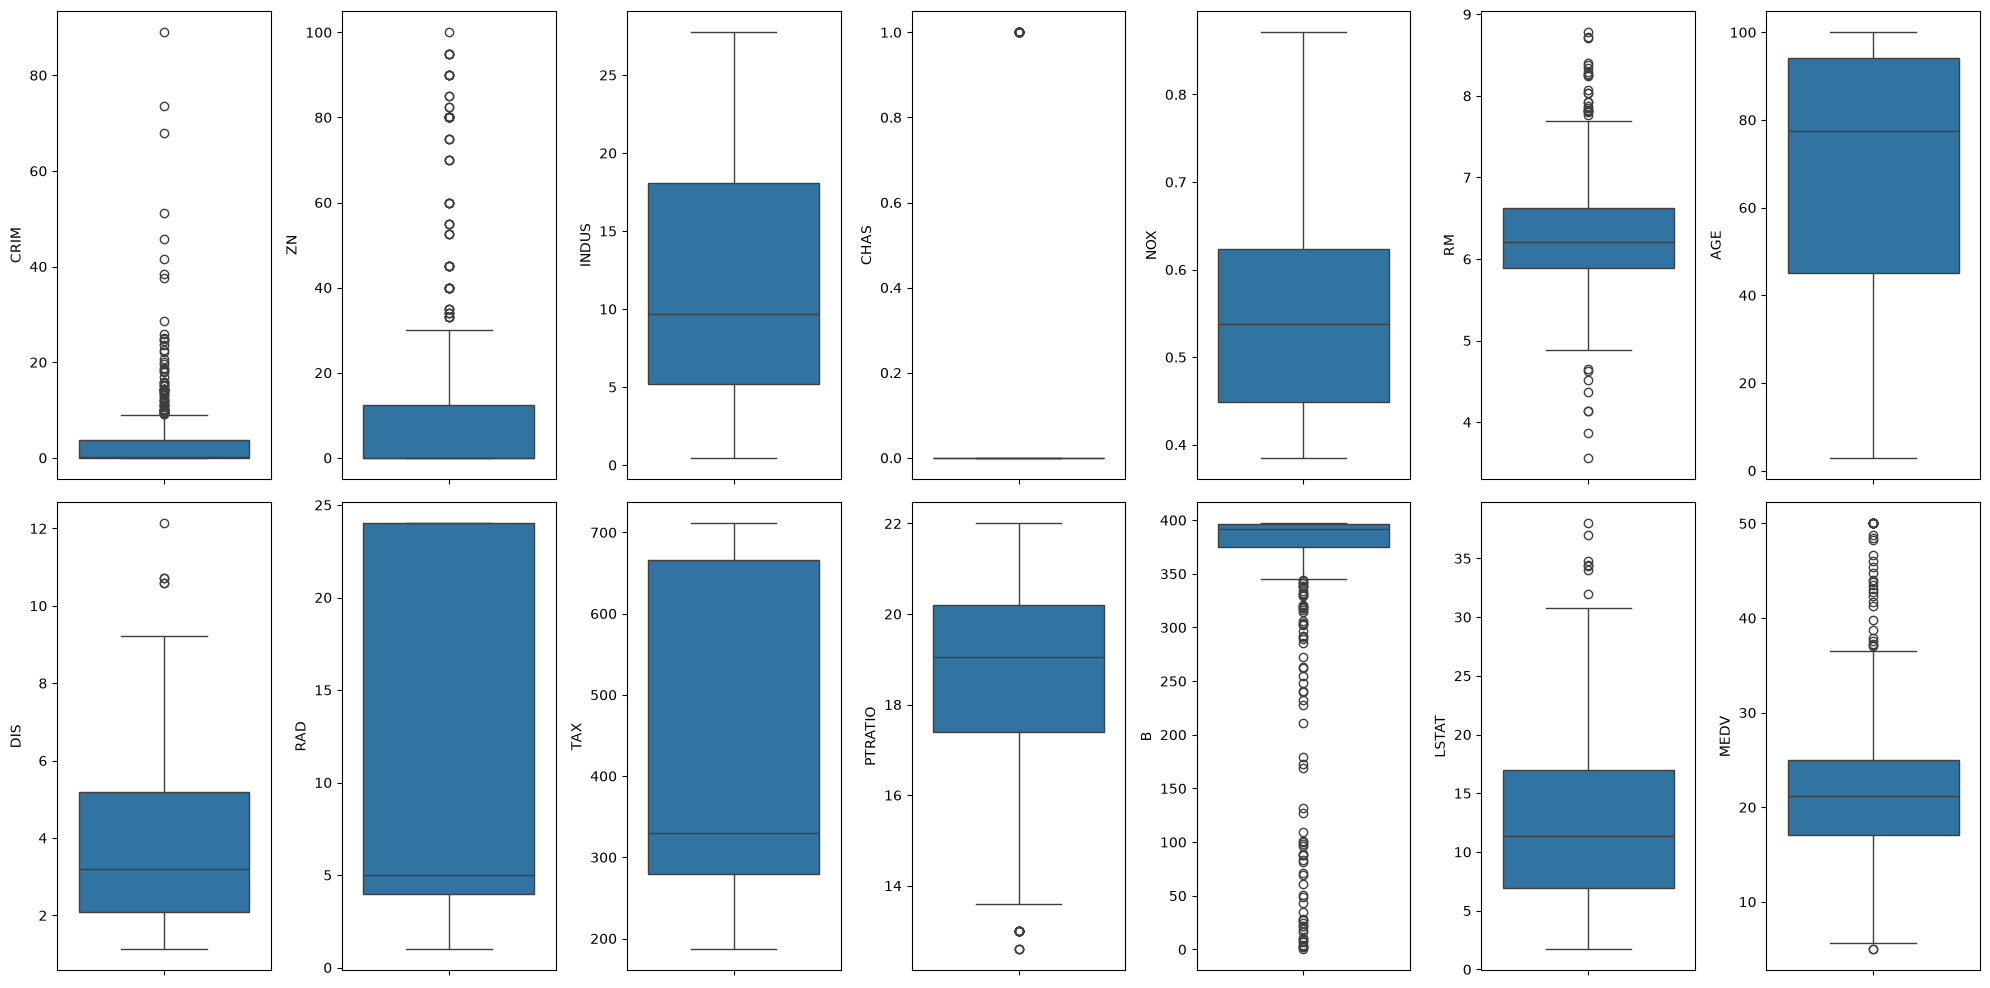

In [8]:
fig, axes = plt.subplots(nrows=2, ncols=7, figsize=(20, 10))
for column, ax in zip(df.columns, axes.flat):
    sns.boxplot(y=column, data=df, ax=ax)
fig.tight_layout()
plt.show()

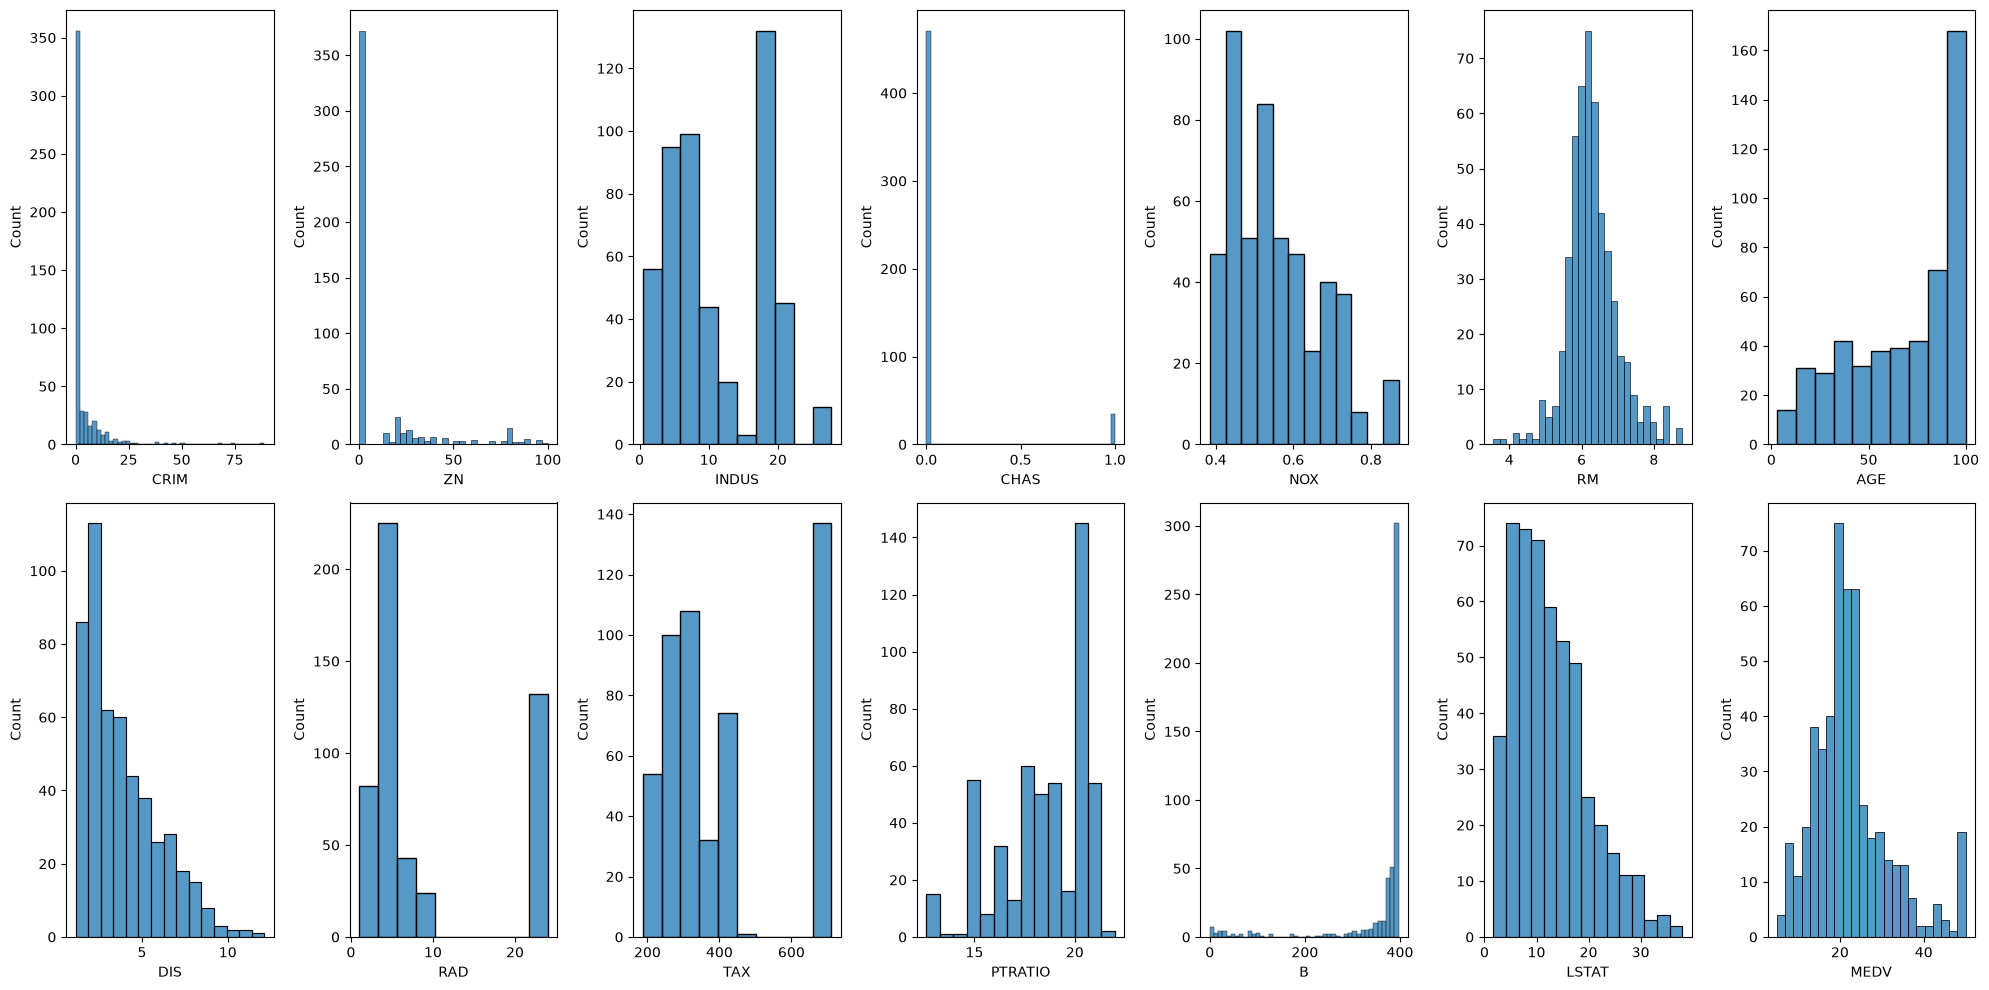

In [9]:
fig, axes = plt.subplots(nrows=2, ncols=7, figsize=(20, 10))
for column, ax in zip(df.columns, axes.flat):
    sns.histplot(df[column], ax=ax)
fig.tight_layout()
plt.show()

## Correlations with home value

The heatmap shows signed Pearson correlations. Rank the features by the magnitude of their correlation with `MEDV` to see strong negative relationships alongside positive ones.

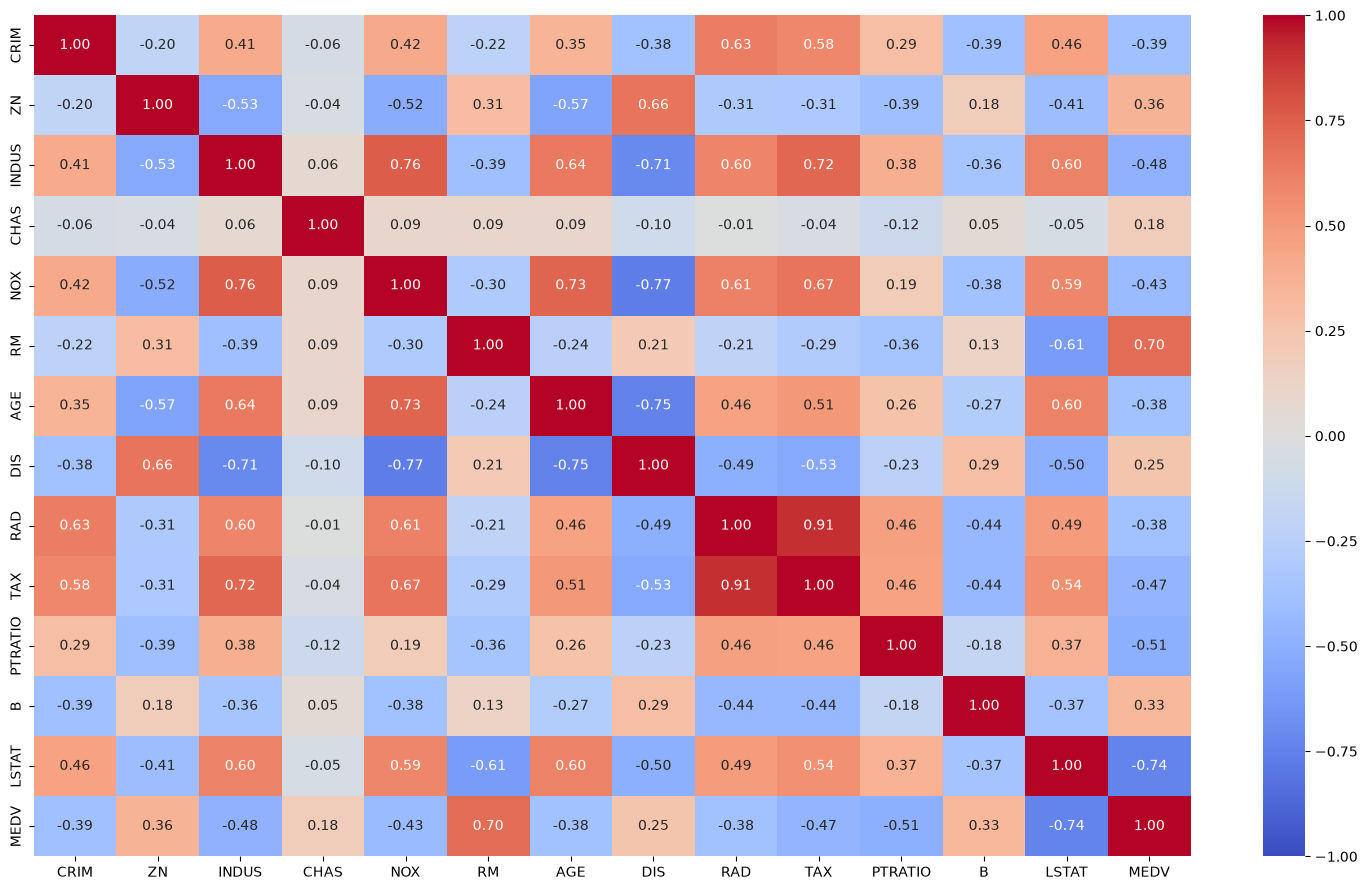

In [10]:
corr = df.corr()
plt.figure(figsize=(15, 9))
sns.heatmap(corr, annot=True, cmap="coolwarm", center=0, vmin=-1, vmax=1, fmt=".2f")
plt.tight_layout()
plt.show()

In [11]:
target_corr = corr[target].drop(target)
top_features = target_corr.abs().nlargest(5).index
target_corr.loc[top_features]

LSTAT     -0.737663
RM         0.695360
PTRATIO   -0.507787
INDUS     -0.483725
TAX       -0.468536
Name: MEDV, dtype: float64

## Feature plots

Rescale the selected features to the range [0, 1] for plotting. The lines summarize the relationship between each feature and `MEDV` in this dataset.

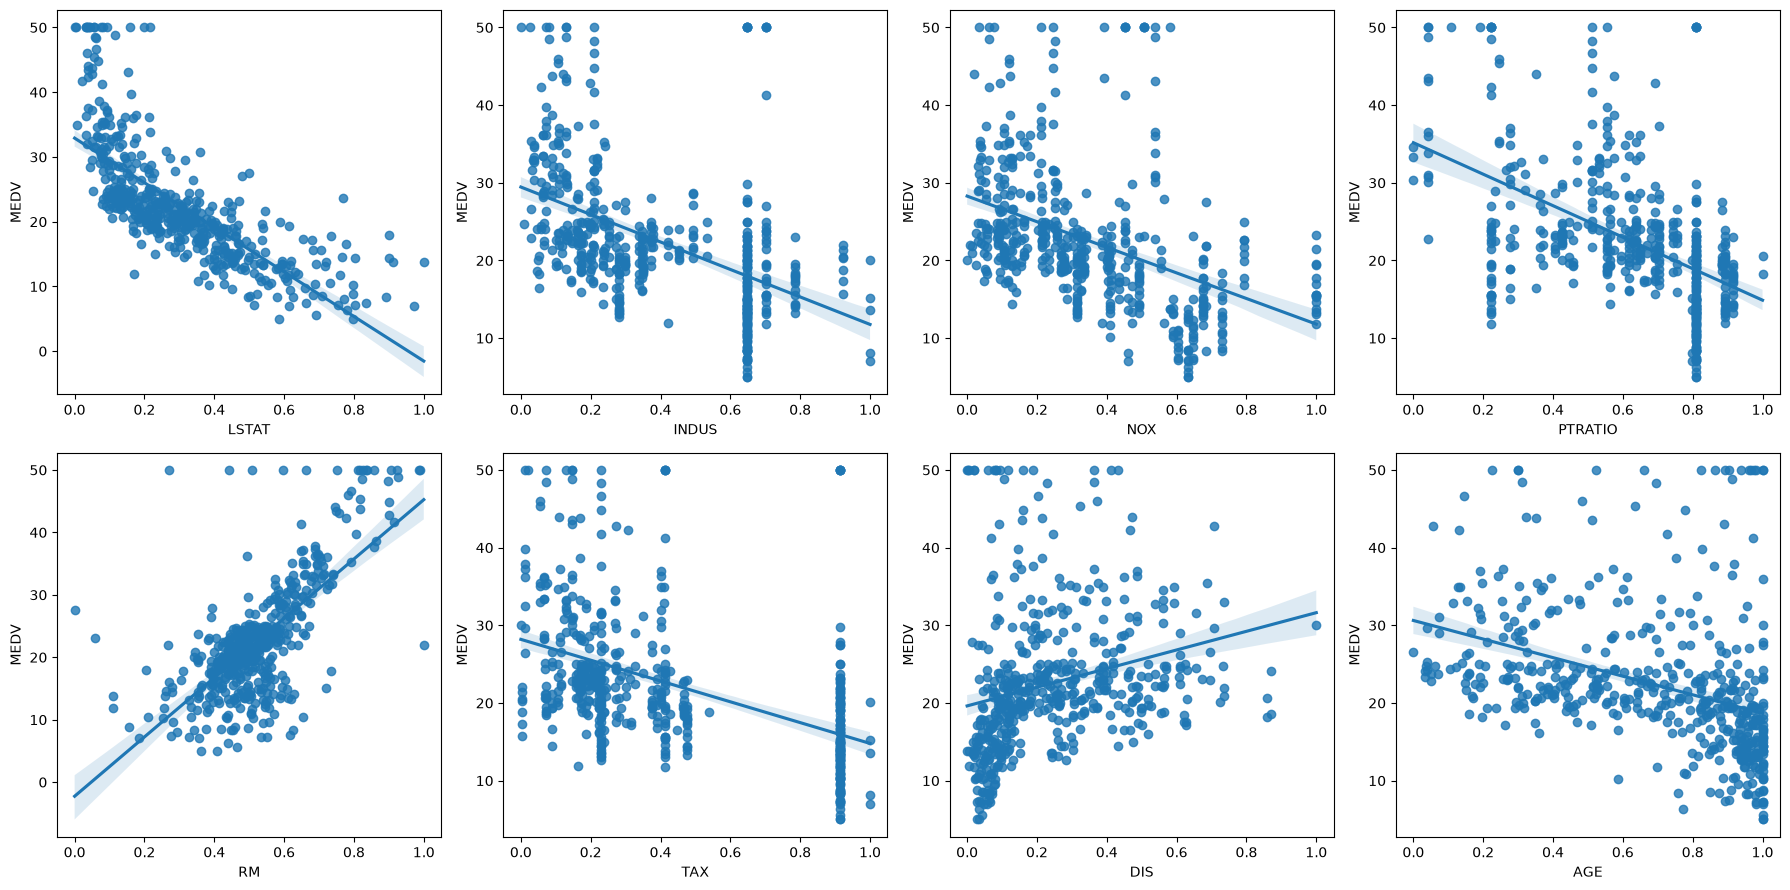

In [12]:
from sklearn.preprocessing import MinMaxScaler

features = ["LSTAT", "INDUS", "NOX", "PTRATIO", "RM", "TAX", "DIS", "AGE"]
scaled = pd.DataFrame(
    MinMaxScaler().fit_transform(df[features]),
    columns=features,
    index=df.index,
)
fig, axes = plt.subplots(nrows=2, ncols=4, figsize=(18, 9))
for feature, ax in zip(features, axes.flat):
    sns.regplot(x=scaled[feature], y=df[target], ax=ax)
fig.tight_layout()
plt.show()